## 1. Import Data


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score




## 1. Load Dataset


In [2]:
df = pd.read_csv("cleaned_dataset.csv")


## 2. Prepare Data

In [3]:
model_data = df[["clean_text", "Label"]].copy()

X = model_data["clean_text"]
y = model_data["Label"]

## 3. Split the Data



In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1780
Testing samples: 445


## 4. Build the Baseline Model


In [5]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("Baseline Accuracy:", round(baseline_accuracy, 4))

Baseline Accuracy: 0.2292


## 5. TF-IDF and Logistic Regression


In [6]:
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


## 6. Make Predictions

In [7]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[4 2 2 4 1 2 2 2 3 2]


## 7. Evaluate the Model


In [8]:
model_accuracy = accuracy_score(y_test, y_pred)
model_precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
model_recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
model_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("Accuracy:", round(model_accuracy, 4))
print("Precision:", round(model_precision, 4))
print("Recall:", round(model_recall, 4))
print("F1-score:", round(model_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9753
Precision: 0.9754
Recall: 0.9753
F1-score: 0.9752

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        84
           1       0.97      1.00      0.99       102
           2       0.97      0.96      0.97        80
           3       0.99      0.96      0.97        77
           4       0.97      0.97      0.97       102

    accuracy                           0.98       445
   macro avg       0.98      0.97      0.97       445
weighted avg       0.98      0.98      0.98       445



## 8. Create an Evaluation Function

In [9]:
def evaluate_model(y_true: pd.Series, y_pred: pd.Series) -> dict[str, float]:
    """Calculate classification evaluation metrics.

    Args:
        y_true: The correct labels.
        y_pred: The labels predicted by the model.

    Returns:
        A dictionary containing accuracy, precision, recall, and F1-score.
    """
    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

    return results


model_results = evaluate_model(y_test, y_pred)

for metric, score in model_results.items():
    print(f"{metric}: {score:.4f}")

Accuracy: 0.9753
Precision: 0.9754
Recall: 0.9753
F1-score: 0.9752


## 9. Compare Baseline and TF-IDF Model


In [10]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "TF-IDF + Logistic Regression"],
    "Accuracy": [baseline_accuracy, model_accuracy]
})

comparison

,Model,Accuracy
0,Baseline,0.229213
1,TF-IDF + Logistic Regression,0.975281


## 10. Model Accuracy Visualization

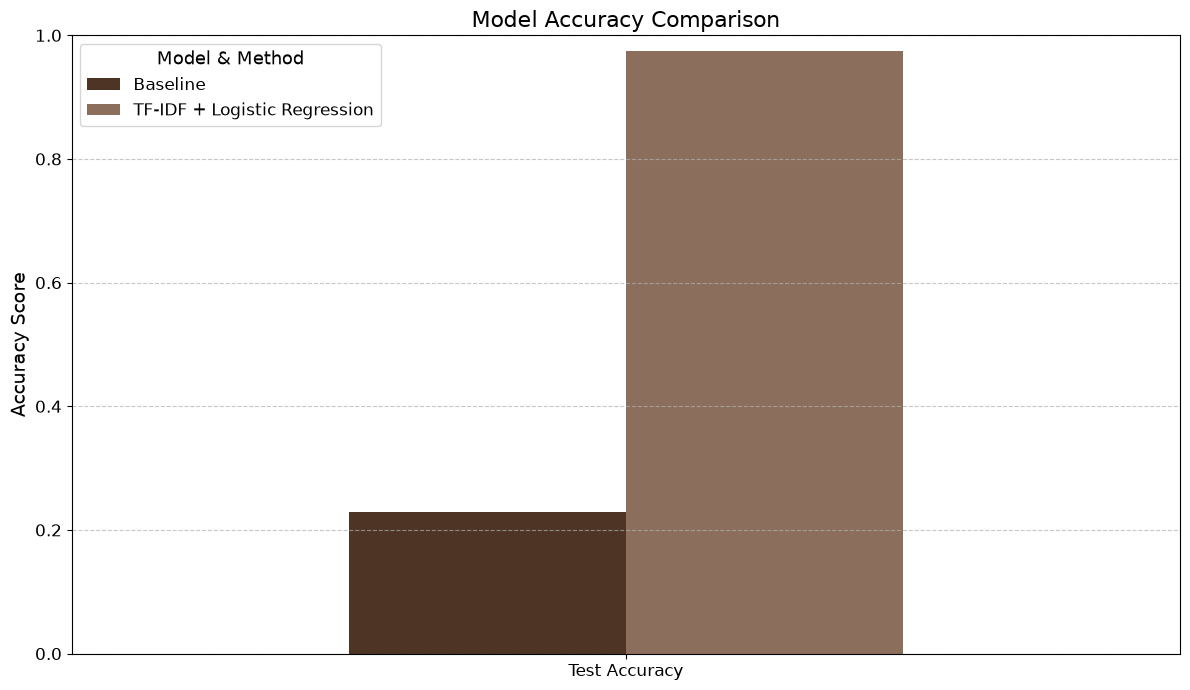

In [11]:

import matplotlib.pyplot as plt

# Create data for the chart
chart_data = pd.DataFrame({
    "Baseline": [baseline_accuracy],
    "TF-IDF + Logistic Regression": [model_accuracy]
}, index=["Test Accuracy"])

# Plot the comparison
ax = chart_data.plot(
    kind="bar",
    figsize=(12, 7),
    color=["#4D3425", "#8B6F5C"]
)

plt.title("Model Accuracy Comparison", fontsize=16)
plt.ylabel("Accuracy Score", fontsize=14)
plt.ylim(0, 1)
plt.xticks(rotation=0, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title="Model & Method", fontsize=12, title_fontsize=13)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()
